In [595]:
import numpy as np
import matplotlib.pyplot as plt
import os


**First working with single variable dataset**

The first dataset contains two columns, first is the population of a city (in 10,000s) and second is the amount of profit (in $10,000). The goal is to predict the amount of profit in cities based on a certain number of population. Profit being the target and population being the single input variable.

In [596]:
data = np.loadtxt(os.path.join('Data', 'ex1data1.txt'), delimiter = ',')
X, y = data[:, 0], data[:, 1]

lets plot the data points

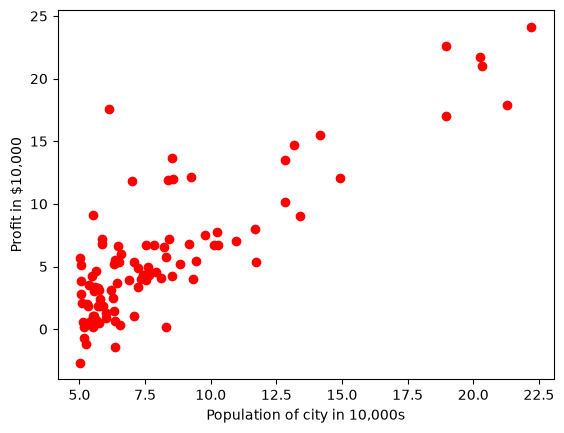

In [597]:
plt.scatter(X, y, c = 'r')
plt.xlabel('Population of city in 10,000s')
plt.ylabel('Profit in $10,000')
plt.show()

For this entire project I will be using Mean Squared Error (MSE) loss function. We know a linear regression model for single variable is defined by a line fx = wx + b where w is the weight, b is the bias or intercept term and x is the input data. Fx(x) defines our prediction for weight w and bias b. Here, I'll be adding an extra column of ones in X for the bias term to match the dimension of weight array.

In [598]:
ones = np.ones((X.shape[0]))
X = np.stack([ones, X], axis = 1)
m, n = X.shape

**Implementing the cost/loss function for MSE:-**

$$ J(w) = \frac{1}{2m} \sum_{i=1}^m \left( f_{w}(x^{(i)}) - y^{(i)}\right)^2$$



In [599]:
def singleCost(X, y, w):
    """ 
        X: This refers to the input data of dimension (m, n)
        y: The target feature of dimension (m,)
        w: array containing all the weights of dimension (n,)

    """
    J = 0

    for i in range(m):
        pred = np.dot(X[i], w)
        J += (pred - y[i]) ** 2

    J /= 2 * m
    return J

Calculating loss with initial weights of 0.

In [600]:
loss = singleCost(X, y, w = np.array([0, 0]))
loss

np.float64(32.072733877455654)

Now, lets find the appropriate values for our weights using gradient descent using the formula:- 


$$w_j = w_j - \alpha \frac{\partial J(w)}{\partial w_j}$$


Where, 


$$\frac{\partial J(w)}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} \left( f(x^{(i)}) - y^{(i)} \right) x_j^{(i)}$$


**So, our new revised formula is:-**


$$w_j = w_j - \alpha \frac{1}{m} \sum_{i=1}^{m} \left( f(x^{(i)}) - y^{(i)} \right) x_j^{(i)}$$

Implementing a function to calculate gradients first

In [601]:
def calculateGradient(X, y, w):

    # make an array to store gradients for each feature
    dj_dw = np.zeros(n)

    # For each row
    for i in range(m):
        # Calculate the error
        err = np.dot(X[i], w) - y[i]
        # For each row's each columns
        for j in range(n):
            dj_dw[j] += err * X[i][j]

    dj_dw /= m

    return dj_dw

Now, implementing gradient descent

In [602]:
def gradientDescent(X, y, w, alpha, iterations):
    """

        alpha: Learning rate
        iterations: Number of iterations to run gradient descent
    
    """
    w = w.copy()

    # A list containing cost history in each iteration of gradient descent
    J_History = []

    for i in range(iterations):

        dj_dw = calculateGradient(X, y, w)

        w = w - alpha * dj_dw

        J_History.append(singleCost(X, y, w))


    return w, J_History

Now, lets run it with initial weights of zero

In [603]:
# Here the number of iterations should be chosen in such a way that the weights converge 
iterations = 3000
alpha = 0.005
w = np.zeros(n)

new_w, history = gradientDescent(X, y, w, alpha, iterations)

print(f'Calculated values of weights: {new_w}')

Calculated values of weights: [-3.62996716  1.16632977]


Now, lets plot the model and see if it fits the dataset

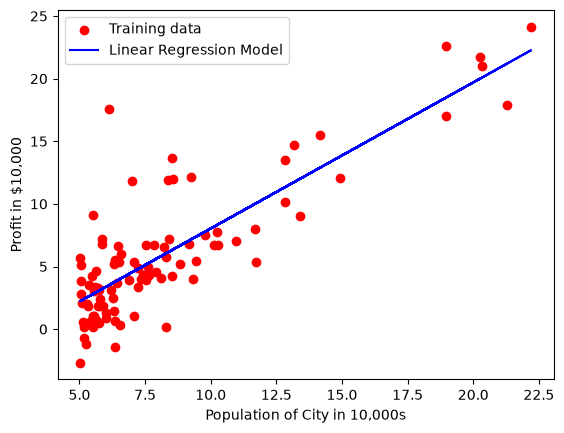

In [604]:
plt.scatter(X[:, 1], y, c='r', label = 'Training data')
plt.plot(X[:, 1], np.dot(X, new_w), c='b', label = 'Linear Regression Model')
plt.xlabel('Population of City in 10,000s')
plt.ylabel('Profit in $10,000')
plt.legend()
plt.show()

We can clearly see that the model fits our training data decently well


**Lets also visualize how our cost changed overtime**

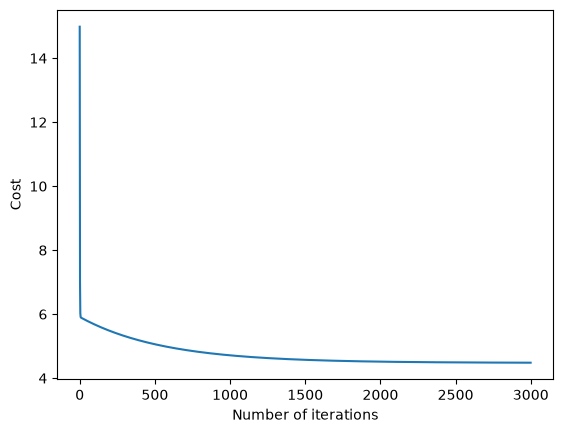

In [605]:
plt.plot(np.arange(iterations), history)
plt.xlabel('Number of iterations')
plt.ylabel('Cost')
plt.show()

Here, we can clearly see that the cost gradually decreases and converges at ~2000 iterations. So, our gradient descent performed well.

Lets now predict profit using new inputs

In [ ]:
# Predict profit of a city with a population of 35000 and 75000

pred1 = np.dot([1, 3.5], new_w)
pred2 = np.dot([1, 7], new_w)

print(f"The profit in a city with a population of 35000 is ${pred1*10000:.2f}\n")
print(f"The profit in a city with a population of 75000 is ${pred2*10000:.2f}")


The profit in a city with a population of 35000 is $4521.87

The profit in a city with a population of 75000 is $45343.41
